In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    if model_name in ('rewBV2006', 'rewBV2006ang'):
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    else:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# functions for analysis of chemical shifts
# functions for chemical shift analysis
# Constants
# from here : https://link.springer.com/article/10.1007/s10858-010-9433-9 (average prediction error of the forward model)
CS_UNCERTAINTIES = {
    "Sparta+": {"C": 1.09, "CA": 0.94, "CB": 1.14, "N": 2.45, "H": 0.49, "HA": 0.25}
}

AA_dict = {
    "A": "ALA",  # Alanine
    "R": "ARG",  # Arginine
    "N": "ASN",  # Asparagine
    "D": "ASP",  # Aspartic Acid
    "C": "CYS",  # Cysteine
    "E": "GLU",  # Glutamic Acid
    "Q": "GLN",  # Glutamine
    "G": "GLY",  # Glycine
    "H": "HIS",  # Histidine
    "I": "ILE",  # Isoleucine
    "L": "LEU",  # Leucine
    "K": "LYS",  # Lysine
    "M": "MET",  # Methionine
    "F": "PHE",  # Phenylalanine
    "P": "PRO",  # Proline
    "S": "SER",  # Serine
    "T": "THR",  # Threonine
    "W": "TRP",  # Tryptophan
    "Y": "TYR",  # Tyrosine
    "V": "VAL",  # Valine
}

# atom types to use during reweighting: choose from [ HA CA HN N C CB ]
ATOM_TYPES = ["CA", "HA", "CB", "HN", "N", "C", "H"] # HN and H present because "H" is used in potenci shift tables
ATOM_TYPES = ["CA"] 

def load_experimental_shifts(path: str, ATOM_TYPES) -> Dict[Tuple[int, str], float]:
    """Load experimental chemical shifts. Returns first column is 'resSeq', second is 'name', third is 'value'."""
    df = pd.read_csv(path, delim_whitespace=True)
    residues = []
    names = []
    values = []
    for i in range(len(df)):
        res = int(df['#RESID'][i])
        for col in df.columns[2:]:
            if col in ATOM_TYPES: # only including specified nuclei
                if col=='HN':
                    try:
                        value = float(df[col][i])
                        if value>0:
                            residues.append(res)
                            names.append('H') # rename HN to H
                            values.append(value)
                    except:
                        continue
                else:
                    try:
                        value = float(df[col][i])
                        if value>0:
                            residues.append(res)
                            names.append(col)
                            values.append(value)
                    except:
                        continue
            else:
                continue
    return {(int(res), str(name)): float(value) for res, name, value in zip(residues, names, values)}

def load_and_filter_experimental_shifts(path: str, bmrb_stats_path: str, sigma_cutoff = 3.0, ATOM_TYPES = ATOM_TYPES) -> Dict[Tuple[int, str], float]:
    """Load experimental chemical shifts. Returns first column is 'resSeq', second is 'name', third is 'value'."""
    df = pd.read_csv(path, delim_whitespace=True)
    bmrb = pd.read_csv(bmrb_stats_path)
    residues = []
    names = []
    values = []
    for i in range(len(df)):
        res = int(df['#RESID'][i])
        resname = str(df['RESNAME'][i])
        if len(resname)==1:
            resname = AA_dict[resname] # convert to 3-letter code if 1-letter
        for col in df.columns[2:]:
            if col in ATOM_TYPES: # only including specified nuclei
                try:
                    value = float(df[col][i])
                    if value>0:
                        # extract bmrb avg and sd
                        if col=='HN':
                            row = bmrb[(bmrb["comp_id"] == resname) & (bmrb["atom_id"] == 'H')]
                            bmrb_mu = row["avg"].values[0]
                            bmrb_sd = row["std"].values[0]
                            if np.abs(value - bmrb_mu) < bmrb_sd * sigma_cutoff:
                                residues.append(res)
                                names.append('H') # rename HN to H
                                values.append(value)
                        else:
                            row = bmrb[(bmrb["comp_id"] == resname) & (bmrb["atom_id"] == col)]
                            bmrb_mu = row["avg"].values[0]
                            bmrb_sd = row["std"].values[0]
                            if np.abs(value - bmrb_mu) < bmrb_sd * sigma_cutoff:
                                residues.append(res)
                                names.append(col)
                                values.append(value)
                except:
                    continue
            else:
                continue
    return {(int(res), str(name)): float(value) for res, name, value in zip(residues, names, values)}

def load_potenci_shifts(path: str, ATOM_TYPES = ATOM_TYPES) -> Dict[Tuple[int, str], float]:
    """Load experimental chemical shifts. Returns first column is 'resSeq', second is 'name', third is 'value'."""
    df = pd.read_csv(path, delim_whitespace=True)
    residues = []
    names = []
    values = []
    for i in range(len(df)):
        res = int(df['#NUM'][i])
        for col in df.columns[2:]:
            if col in ATOM_TYPES: # only including specified nuclei
                try:
                    value = float(df[col][i])
                    if value>0:
                        residues.append(res)
                        names.append(col)
                        values.append(value)
                except:
                    continue
            else:
                continue
    return {(int(res), str(name)): float(value) for res, name, value in zip(residues, names, values)}

def load_generated_shifts(path: str) -> pd.DataFrame:
    """
    Load generated shifts from a CSV file.
    Assumes columns: resSeq, name, 0, 1, 2, ..., representing one residue/atom per row and frames across columns.
    Returns DataFrame indexed by (resSeq, name), with frames as columns.
    """
    df = pd.read_csv(path)
    df["resSeq"] = df["resSeq"].astype(int)
    df["name"] = df["name"].astype(str)
    df.set_index(["resSeq", "name"], inplace=True)
    return df

def standardize_deltas(gen_df: pd.DataFrame, exp_dict: Dict[Tuple[int, str], float],
                       predictor: str = "Sparta+") -> Tuple[np.ndarray, list]:
    cs_uncertainties = CS_UNCERTAINTIES[predictor]
    keys = sorted(set(exp_dict).intersection(set(gen_df.index)))

    
    std_devs = np.array([cs_uncertainties[a] for (_, a) in keys]).reshape(-1, 1)
    
    exp_vals = np.array([exp_dict[k] for k in keys]).reshape(-1, 1)
    gen_vals = gen_df.loc[keys].values  # shape: (n_obs, n_frames)
    std_delta = (gen_vals - exp_vals) / std_devs
    return std_delta, keys

# function to calculate the difference between experiment and simulation: CALC - EXP
def raw_diff(gen_df: pd.DataFrame, exp_dict: Dict[Tuple[int, str], float]):
    keys = sorted(set(exp_dict).intersection(set(gen_df.index)))
    exp_vals = np.array([exp_dict[k] for k in keys]).reshape(-1, 1)
    gen_vals = gen_df.loc[keys].values  # shape: (n_obs, n_frames)
    diff = gen_vals - exp_vals

    return diff, keys

def get_RMSE(
    std_delta_cs: np.ndarray,  # shape (n_obs, n_samples)
    weights: np.ndarray = None,  # shape (n_samples,)
    order: int = 2,  # order of the norm
) -> float:
    """Root Mean Square Error."""
    assert len(std_delta_cs.shape) == 2
    mask_nan = ~np.isnan(std_delta_cs).any(axis=0)
    if weights is None:
        return np.linalg.norm(np.average(std_delta_cs[:, mask_nan], axis=1), ord=order) / np.power(
            len(std_delta_cs),
            1 / order,
        )
    mask_nan_weights = ~np.isnan(weights)
    if weights[mask_nan_weights & (~mask_nan)].sum() != 0:
        print("+++ WARNING: samples with NaN chemical shifts should have 0 weight")
    mask_nan = mask_nan & mask_nan_weights
    if not mask_nan.any():  # this happens if the optimization failed
        return np.nan
    return np.linalg.norm(
        np.average(std_delta_cs[:, mask_nan], weights=weights[mask_nan], axis=1),
        ord=order,
    ) / np.power(len(std_delta_cs), 1 / order)

path = '../'

#####################
### EXAMPLE USAGE ###
#####################


#gen_df = load_generated_shifts(predfile)
#exp_dict = load_and_filter_experimental_shifts(expfile, bmrb_stats_path=bmrb_stats_path)

#std_delta_cs, keys = standardize_deltas(gen_df, exp_dict, predictor = CS_predictor)
#print(std_delta_cs.shape)
#print(get_RMSE(std_delta_cs))
#print(get_RMSE(std_delta_cs[:, ~np.isnan(weights_nan)]))
#print(get_RMSE(std_delta_cs, weights=np.repeat(1, std_delta_cs.shape[1])))


outpath='./HP36_plots/'


/tmp/ipykernel_914688/1522128797.py:141: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  amides = np.loadtxt(f"../../MD_DATA/{protein}/{model}/amideresidues.txt", dtype=int)
/tmp/ipykernel_914688/1522128797.py:141: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating 

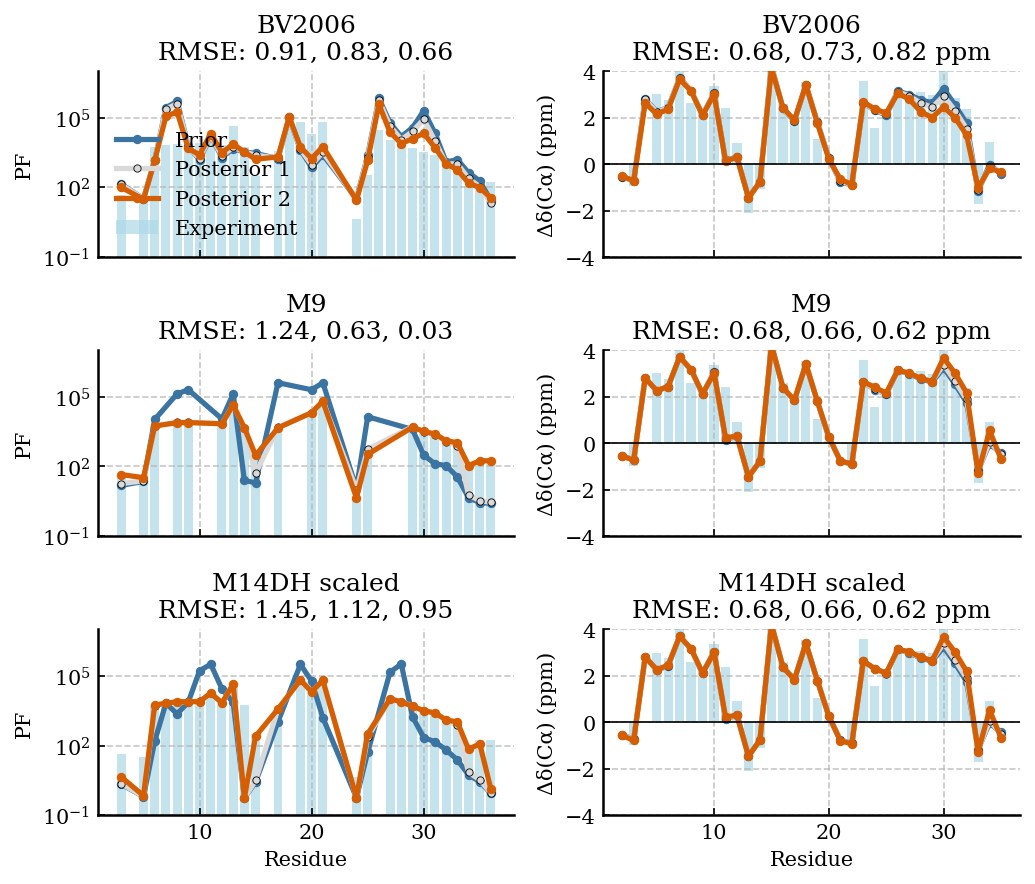

In [4]:


# --------------------------------------------------
# Models and protein
# --------------------------------------------------
protein = "HP36"
models = ["rewBV2006", "rewM9", "rewM14DH_scaled"]
model_labels = ["BV2006", "M9", "M14DH scaled"]
nucleus = "CA"

# --------------------------------------------------
# Colours
# --------------------------------------------------
COLOR3 = "#3B73A1"  # prior
COLOR1 = "#D55E00"  # posterior 1: elbow
COLOR2 = "#D9D9D9"  # posterior 2
EXP_COLOR = "lightblue"

# --------------------------------------------------
# Chemical-shift settings
# --------------------------------------------------
all_types = ["CA", "CB", "HA", "C", "H", "HN", "N"]
label_dict = {"CA": "Cα", "HA": "Hα", "CB": "Cβ", "C": "C'"}
axlim_dict = {"CA": 4, "HA": 1, "CB": 4, "C": 4}

# --------------------------------------------------
# Helper for weighted PF calculations for open state models
# --------------------------------------------------
def calculate_weighted_pf(model_dir, weights, residue_indices=None):
    candidate_files = ["fopen.npy", "fopenDH.npy", "O.npy"]
    observable_file = next((f"{model_dir}/{name}" for name in candidate_files if os.path.exists(f"{model_dir}/{name}")), None)

    if observable_file is None:
        raise FileNotFoundError(f"No per-frame PF observable found in {model_dir}. Expected one of: {candidate_files}")

    observable = np.load(observable_file)

    if observable.shape[0] != len(weights) and observable.shape[1] == len(weights):
        observable = observable.T

    if observable.shape[0] != len(weights):
        raise ValueError(f"Weight length {len(weights)} does not match observable shape {observable.shape} for {model_dir}")

    filename = os.path.basename(observable_file)

    
    predicted_pf = 1.0 / np.average(observable, weights=weights, axis=0)

    if residue_indices is not None:
        predicted_pf = predicted_pf[residue_indices]

    return predicted_pf

# and BV model
def calculate_weighted_pf_bv(model_dir, weights, residue_indices=None):
    contacts, hbonds = np.load(model_dir + "/contacts_res_frames.npy"), np.load(model_dir + "/hbonds_res_frames.npy")

    lnPF = 0.35* contacts + 2.00 * hbonds

    predicted_pf = np.exp(np.average(lnPF, weights=weights, axis=0))

    if residue_indices is not None:
        predicted_pf = predicted_pf[residue_indices]

    return predicted_pf

# --------------------------------------------------
# Load calculated chemical shifts
# --------------------------------------------------
traj_names = np.sort(find_xtc_filenames(f"../../MD_DATA/{protein}/"))

for i, traj_name in enumerate(traj_names):
    shift_file = f"../../MD_DATA/{protein}/CS/CS_{traj_name[:-4]}.csv"
    tmp_df = load_generated_shifts(shift_file)
    gen_df = tmp_df if i == 0 else pd.concat([gen_df, tmp_df], axis=1, join="outer", ignore_index=True)

# --------------------------------------------------
# Load experimental and random-coil chemical shifts
# --------------------------------------------------
exp_dict = load_and_filter_experimental_shifts(f"../../ORTHOGONAL_EXP_DATA/{protein}/CS.dat", "../../code/cs_stat_aa_filt.csv", ATOM_TYPES=all_types)
potenci = load_potenci_shifts(f"../../ORTHOGONAL_EXP_DATA/potenci_shifts/{protein}_RCshifts.dat", ATOM_TYPES=all_types)

potenci_residues = np.array([key[0] for key in potenci if key[1] == nucleus])
potenci_shifts = np.array([potenci[key] for key in potenci if key[1] == nucleus])
exp_residues = np.array([key[0] for key in exp_dict if key[1] == nucleus])
exp_shifts = np.array([exp_dict[key] for key in exp_dict if key[1] == nucleus])

potenci_order = np.argsort(potenci_residues)
exp_order = np.argsort(exp_residues)
potenci_residues = potenci_residues[potenci_order]
potenci_shifts = potenci_shifts[potenci_order]
exp_residues = exp_residues[exp_order]
exp_shifts = exp_shifts[exp_order]

common_residues = np.intersect1d(potenci_residues, exp_residues)
indices_p = np.where(np.isin(potenci_residues, common_residues))[0]
indices_e = np.where(np.isin(exp_residues, common_residues))[0]
SSexp = exp_shifts[indices_e] - potenci_shifts[indices_p]

# --------------------------------------------------
# Prepare calculated chemical-shift arrays
# --------------------------------------------------
calc_vals = []
calc_residues = []

for residue in potenci_residues:
    try:
        calc_vals.append(np.asarray(gen_df.loc[residue, nucleus], dtype=float))
        calc_residues.append(residue)
    except KeyError:
        continue

calc_residues = np.array(calc_residues)
calc_vals = np.array(calc_vals).T

indices_p_calc = np.array([np.where(potenci_residues == residue)[0][0] for residue in calc_residues])
potenci_for_calc = potenci_shifts[indices_p_calc]

# --------------------------------------------------
# Create 3 × 2 figure
# --------------------------------------------------
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(7, 6), sharex="col")

for i, (model, model_label) in enumerate(zip(models, model_labels)):
    model_dir = f"../../MD_DATA/{protein}/{model}"

    # --------------------------------------------------
    # Load prior, elbow and final weights
    # --------------------------------------------------
    prior_weights = np.ones(calc_vals.shape[0]) / calc_vals.shape[0]

    if "BV" in model:
        wopt_elbow = np.load(f"{model_dir}/wopt_elbow.npy")
        wopt = np.load(f"{model_dir}/wopt.npy")
    else:
        wopt_elbow = np.load(f"{model_dir}/log_lambda_wopt_elbow.npy")
        wopt = np.load(f"{model_dir}/log_lambda_wopt.npy")

    # --------------------------------------------------
    # Load experimental PFs
    # --------------------------------------------------
    exp, residues, priorPF_loaded, posterior2PF_loaded, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
    amides = np.loadtxt(f"../../MD_DATA/{protein}/{model}/amideresidues.txt", dtype=int)
    amide_idxs = [list(amides).index(ele) for ele in residues if ele in amides]
    expPF = np.asarray(exp["PF"][idxs])
    residues = np.asarray(residues)

    # --------------------------------------------------
    # Calculate prior, elbow and final PF predictions
    # --------------------------------------------------
    if "BV" in model:
        priorPF = calculate_weighted_pf_bv(model_dir, prior_weights, residue_indices=amide_idxs)
        posterior1PF = calculate_weighted_pf_bv(model_dir, wopt_elbow, residue_indices=amide_idxs)
        posterior2PF = calculate_weighted_pf_bv(model_dir, wopt, residue_indices=amide_idxs)
    else:
        priorPF = calculate_weighted_pf(model_dir, prior_weights, residue_indices=amide_idxs)
        posterior1PF = calculate_weighted_pf(model_dir, wopt_elbow, residue_indices=amide_idxs)
        posterior2PF = calculate_weighted_pf(model_dir, wopt, residue_indices=amide_idxs)

    pf_rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
    pf_rmse_posterior1 = RMSE(np.log10(expPF), np.log10(posterior1PF))
    pf_rmse_posterior2 = RMSE(np.log10(expPF), np.log10(posterior2PF))

    # --------------------------------------------------
    # Plot PF profiles
    # --------------------------------------------------
    ax = axes[i, 0]
    
    ax.set_xticks([0, 10, 20, 30])
    ax.set_xticklabels(["0", "10", "20", "30"])
    ax.bar(residues, expPF, width=0.8, color=EXP_COLOR, alpha=0.7, label="Experiment")
    ax.plot(residues, priorPF, color=COLOR3, linewidth=2.5, marker="o", markersize=3.5, label="Prior")
    ax.plot(residues, posterior1PF, color=COLOR2, linewidth=2.5, marker="o", markersize=3.5, markeredgecolor="black", markeredgewidth=0.4, label="Posterior 1")
    ax.plot(residues, posterior2PF, color=COLOR1, linewidth=2.5, marker="o", markersize=3.5, label="Posterior 2")
    ax.set_title(f"{model_label}\nRMSE: {pf_rmse_prior:.2f}, {pf_rmse_posterior1:.2f}, {pf_rmse_posterior2:.2f}")
    ax.set_yscale("log")
    ax.set_ylim(1e-1, 1e7)
    ax.set_ylabel("PF")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", which="both", top=False, right=False)
    ax.yaxis.set_ticks_position("left")

    # --------------------------------------------------
    # Calculate secondary carbonyl chemical shifts
    # --------------------------------------------------
    prior_cs = np.average(calc_vals, weights=prior_weights, axis=0)
    posterior1_cs = np.average(calc_vals, weights=wopt_elbow, axis=0)
    posterior2_cs = np.average(calc_vals, weights=wopt, axis=0)

    SSprior = prior_cs - potenci_for_calc
    SSposterior1 = posterior1_cs - potenci_for_calc
    SSposterior2 = posterior2_cs - potenci_for_calc

    common_calc_exp = np.intersect1d(calc_residues, common_residues)
    calc_common_indices = np.array([np.where(calc_residues == residue)[0][0] for residue in common_calc_exp])
    exp_common_indices = np.array([np.where(common_residues == residue)[0][0] for residue in common_calc_exp])

    cs_rmse_prior = RMSE(SSexp[exp_common_indices], SSprior[calc_common_indices])
    cs_rmse_posterior1 = RMSE(SSexp[exp_common_indices], SSposterior1[calc_common_indices])
    cs_rmse_posterior2 = RMSE(SSexp[exp_common_indices], SSposterior2[calc_common_indices])

    # --------------------------------------------------
    # Plot carbonyl secondary chemical shifts
    # --------------------------------------------------
    ax = axes[i, 1]
    
    ax.set_xticks([0, 10, 20, 30])
    ax.set_xticklabels(["0", "10", "20", "30"])
    ax.bar(common_residues[1:-1], SSexp[1:-1], width=0.8, color=EXP_COLOR, alpha=0.7, label="Experiment") # only residues 2-14 for AAQAA3
    ax.plot(calc_residues, SSprior, color=COLOR3, linewidth=2.5, marker="o", markersize=3.5, label="Prior")
    ax.plot(calc_residues, SSposterior1, color=COLOR2, linewidth=2.5, marker="o", markersize=3.5, markeredgecolor="black", markeredgewidth=0.4, label="Posterior 1")
    ax.plot(calc_residues, SSposterior2, color=COLOR1, linewidth=2.5, marker="o", markersize=3.5, label="Posterior 2")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{model_label}\nRMSE: {cs_rmse_prior:.2f}, {cs_rmse_posterior1:.2f}, {cs_rmse_posterior2:.2f} ppm")
    ax.set_ylim(-axlim_dict[nucleus], axlim_dict[nucleus])
    ax.set_ylabel(f"Δδ({label_dict[nucleus]}) (ppm)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", top=False, right=False)

axes[-1, 0].set_xlabel("Residue")
axes[-1, 1].set_xlabel("Residue")
axes[0, 0].legend(loc="best", frameon=False)

plt.tight_layout()
plt.savefig(outpath+f"{protein}_PF_CS_BV2006_M9_M14DH_scaled.pdf", dpi=300, bbox_inches="tight")
plt.show()